In [1]:
from ModelSimlink import RadiativeTransitions, Levels
from standard_imports import *
from loaders import index
from plots import adv_plt, splt, interactive
from scipy.optimize import curve_fit
from Tools import LinesManipulator

Call %matplotlib widget
Remember to select "cambiare presentazione" -> "application" in the cells output when you want interactive mode


In [2]:
data = index.load_index_and_data( "TestData/RfPen/20230620" ) + index.load_index_and_data( "TestData/PlasmaBIC/20241031" )
data = [ data[12] ]

Avantes spectrum TestData/RfPen/20230620\New Experiment0005.Raw8 normalized by a factor of 0.200000 s
Avantes spectrum TestData/RfPen/20230620\New Experiment0006.Raw8 normalized by a factor of 0.200000 s
Avantes spectrum TestData/RfPen/20230620\New Experiment0007.Raw8 normalized by a factor of 0.200000 s
Avantes spectrum TestData/RfPen/20230620\New Experiment0008.Raw8 normalized by a factor of 0.200000 s
Avantes spectrum TestData/RfPen/20230620\New Experiment0013.Raw8 normalized by a factor of 0.200000 s
Avantes spectrum TestData/RfPen/20230620\New Experiment0014.Raw8 normalized by a factor of 0.200000 s
Avantes spectrum TestData/RfPen/20230620\New Experiment0015.Raw8 normalized by a factor of 0.200000 s
Avantes spectrum TestData/RfPen/20230620\New Experiment0016.Raw8 normalized by a factor of 0.200000 s
8 rows loaded
Avantes spectrum TestData/PlasmaBIC/20241031\101_6us.RAW8 normalized by a factor of 0.400000 s
Avantes spectrum TestData/PlasmaBIC/20241031\102_6us.RAW8 normalized by a f

In [3]:
calib_base = pd.read_csv('CalibrationData/Calib_20250204_FCUVIR600.csv', index_col = False).to_dict('list')

In [4]:
worker = LinesManipulator.LinesManipulator()

In [5]:
for d in data:
        d['wl_realigned'] = worker.realign_wl( d['avantes']['wl'], d['avantes']['int'] )
        d['int_withoutbaseline'] = worker.remove_baseline( d['avantes']['int'] )
        d['cal'] = worker.estimate_calibration( d['wl_realigned'], d['int_withoutbaseline'], calib_base, all_lines = RadiativeTransitions.RadiativeTransitions().linesList() )
        d['int_calibrated'] = d['cal']['int_calib']

Realigned with y = 0.00x^2 +1.00x +0.90
Initializing class Levels


In [9]:
lines = [l for l in RadiativeTransitions.RadiativeTransitions().linesList() if l['from'].startswith('2p') and l['to'].startswith('1s') ]
len(lines)

29

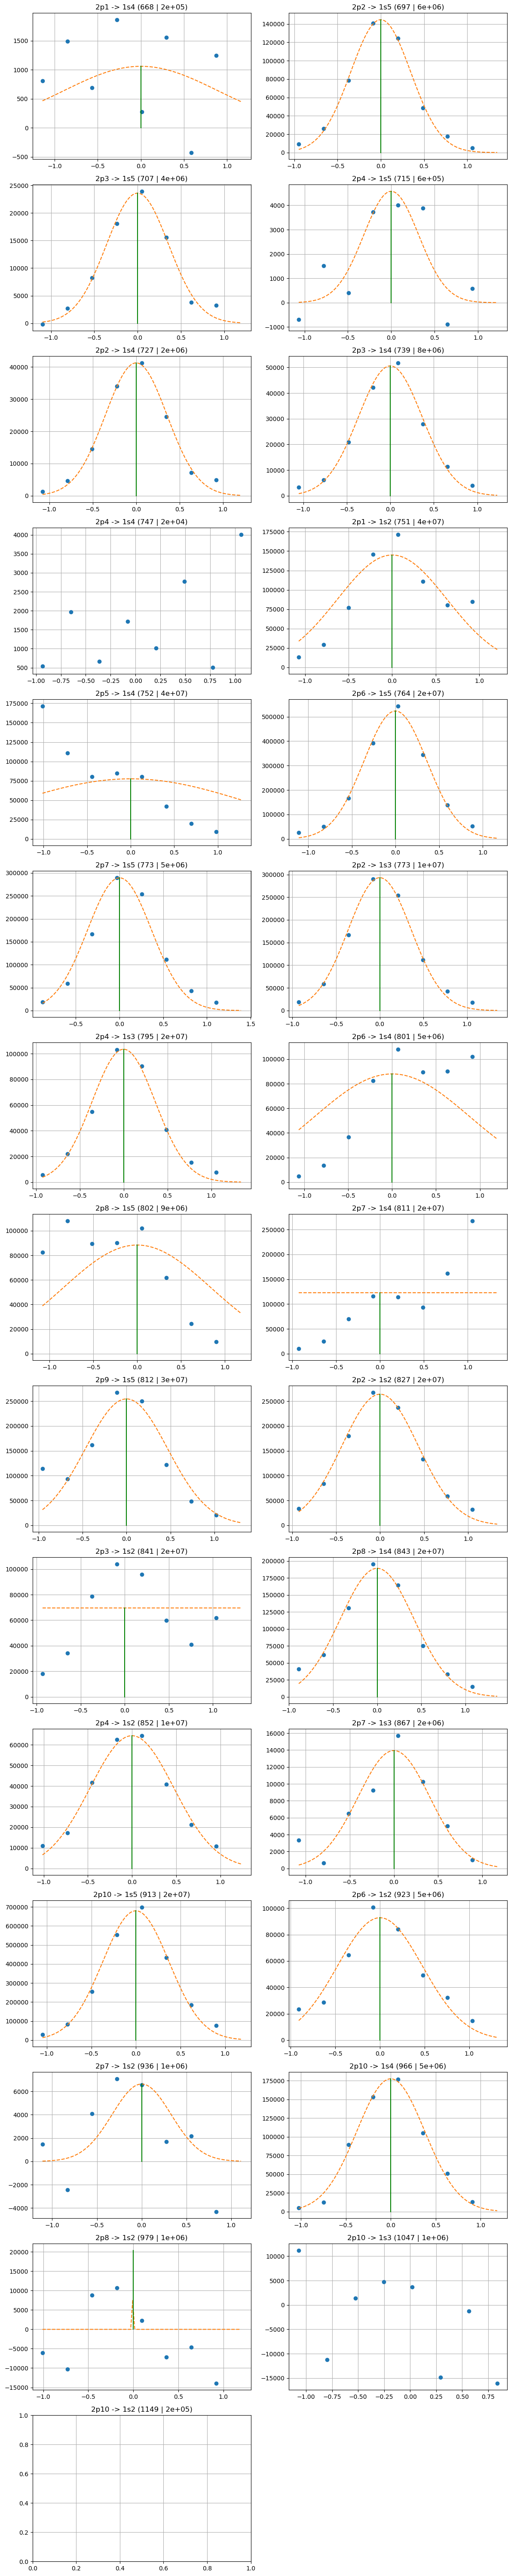

In [15]:
splt.init_bytot( len(lines) * len(data), 2 )

for d in data:
    for l in lines:
        splt.next()

        worker.estimate_amplitude( d['wl_realigned'] - l['wl'], d['int_calibrated'], plot = True )
        plt.title( f'{l["from"]} -> {l["to"]} ({l["wl"]:.0f} | {l["A"]:.0e})' )
        plt.tight_layout()

In [16]:
def doublegauss(x, H, A1, sigma1, A2, sigma2, delta):
    return H + A1 / np.sqrt(2 * np.pi) / sigma1 * np.exp(-x**2 / (2 * sigma1**2) ) + A2 / np.sqrt(2 * np.pi) / sigma2 * np.exp(-(x-delta)**2 / (2 * sigma2**2) )


In [18]:
coupled_lines = { k: [] for k in [ 751, 801, 811, 841 ] }
for l in lines:
    for k in coupled_lines.keys():
        if( np.abs( k - l['wl'] ) < 3 ):
            coupled_lines[k].append( l )

In [24]:
for k in coupled_lines.values():
    for i in k:
        print( f"{i['from']}->{i['to']}")

2p1->1s2
2p5->1s4
2p6->1s4
2p8->1s5
2p7->1s4
2p9->1s5
2p3->1s2
2p8->1s4


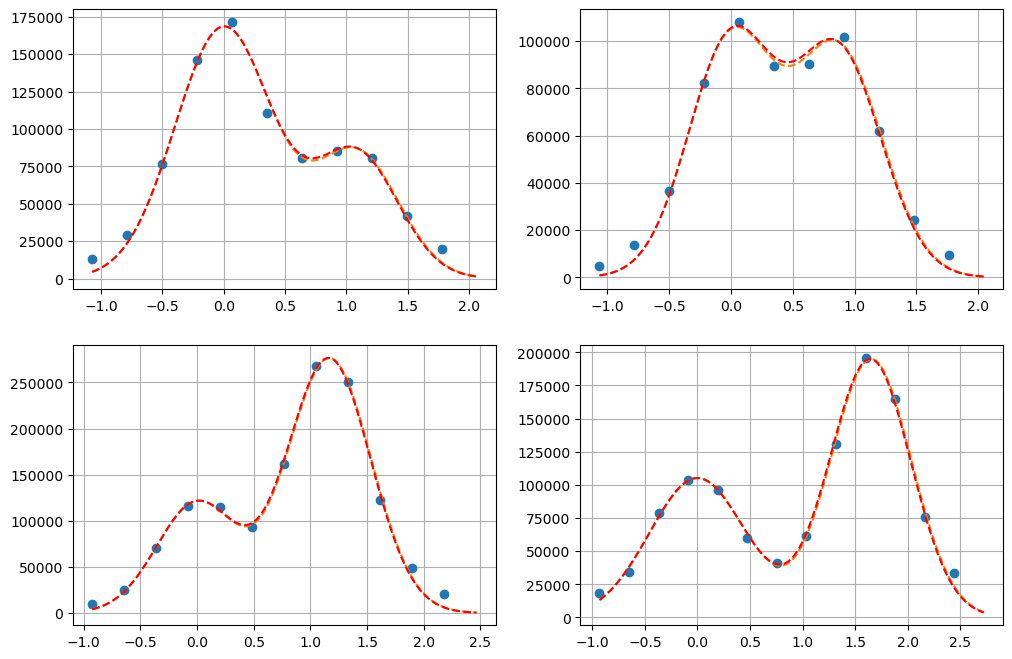

In [22]:
splt.init_bytot( len( data ) * len( coupled_lines ), 2 )

for d in data:
    for cp in coupled_lines.values():
        splt.next()
        assert len( cp ) == 2

        wl_centered = d['wl_realigned'] - cp[0]['wl']
        spec = d['int_calibrated']
        delta_wl = cp[1]['wl'] - cp[0]['wl']

        idx_where = np.where( wl_centered > 0 )[0]
        if( len( idx_where ) < 1 ):
            raise ValueError
        
        idx = np.min( idx_where )
        delta_i = int( delta_wl / ( wl_centered[idx+1] - wl_centered[idx] ) )

        delta = 4
        
        plt.plot(  wl_centered[idx-delta:idx+delta_i+delta], spec[idx-delta:idx+delta_i+delta], 'o')
        xs = np.linspace( wl_centered[idx-delta], wl_centered[idx+delta_i+delta], 200 )
            
        p, pcov = curve_fit( doublegauss, wl_centered[idx-delta:idx+delta_i+delta], spec[idx-delta:idx+delta_i+delta],
                        p0=[ 0, spec[idx], 1, spec[idx+delta_i], 1, delta_wl ],
                        bounds=(
                            [ -0.1, 0, 0, 0, 0, delta_wl - 0.01 ],
                            [ 0.1, np.inf, np.inf, np.inf, np.inf, delta_wl + 0.01 ]
                        ))


        plt.plot( xs, doublegauss( xs, *p ), '--' )
        p[-1] = delta_wl
        plt.plot( xs, doublegauss( xs, *p ), 'r--' )
        # plt.plot( [0,0], [p[0], hvert], 'g')

        # if(error):
        #     return ufloat( p[1], np.sqrt( pcov[1,1] ) )
        # return p[1]
